In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

y_predicted = np.load(r"C:\Users\dhanu\OneDrive\Desktop\data_science_project\4_Model_Training\Model_Predictions_Saved\y_predicted_xgb.npy")
y_predicted_probs = np.load(r"C:\Users\dhanu\OneDrive\Desktop\data_science_project\4_Model_Training\Model_Predictions_Saved\y_predicted_probs_xgb.npy")

y_test = pd.read_csv(r"C:\Users\dhanu\OneDrive\Desktop\data_science_project\4_Model_Training\Training_and_Test_datasets\y_test")
x_test = pd.read_csv(r"C:\Users\dhanu\OneDrive\Desktop\data_science_project\4_Model_Training\Training_and_Test_datasets\x_test")


In [2]:
import joblib
xgb_model = joblib.load(r"C:\Users\dhanu\OneDrive\Desktop\data_science_project\4_Model_Training\Saved_Models\xgb_model")

In [3]:
from sklearn.metrics import classification_report, roc_auc_score, roc_curve, confusion_matrix

# Classification Report
print(classification_report(y_test, y_predicted))

              precision    recall  f1-score   support

           0       0.91      0.75      0.82      1035
           1       0.53      0.79      0.63       374

    accuracy                           0.76      1409
   macro avg       0.72      0.77      0.73      1409
weighted avg       0.81      0.76      0.77      1409



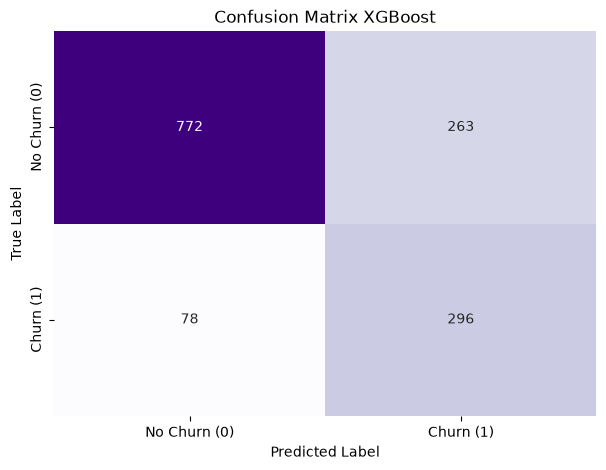

In [4]:
# Confusion Matrix

plt.figure(figsize = (7,5))

cm = confusion_matrix(y_test, y_predicted)
sns.heatmap(cm, annot = True, fmt = 'd', cmap  = "Purples", cbar = False, xticklabels = ["No Churn (0)", "Churn (1)"], yticklabels = ["No Churn (0)", "Churn (1)"])
plt.title("Confusion Matrix XGBoost")
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.show()

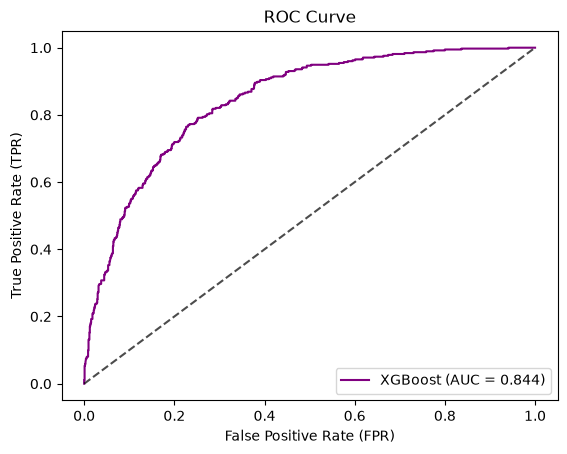

In [5]:
fpr, tpr, _ = roc_curve(y_test, y_predicted_probs)
plt.plot(fpr, tpr, color = 'purple', label = f"XGBoost (AUC = {roc_auc_score(y_test, y_predicted_probs) :.3f})")
plt.plot([0,1], [0,1], 'k--', alpha = 0.7)
plt.title("ROC Curve")
plt.xlabel("False Positive Rate (FPR)")
plt.ylabel("True Positive Rate (TPR)")
plt.legend(loc = 'lower right')
plt.show()

C:\Users\dhanu\AppData\Local\Temp\ipykernel_752\401821494.py:9: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data = feature_imp.head(15), x = 'Importance', y = 'Feature', palette = 'mako')


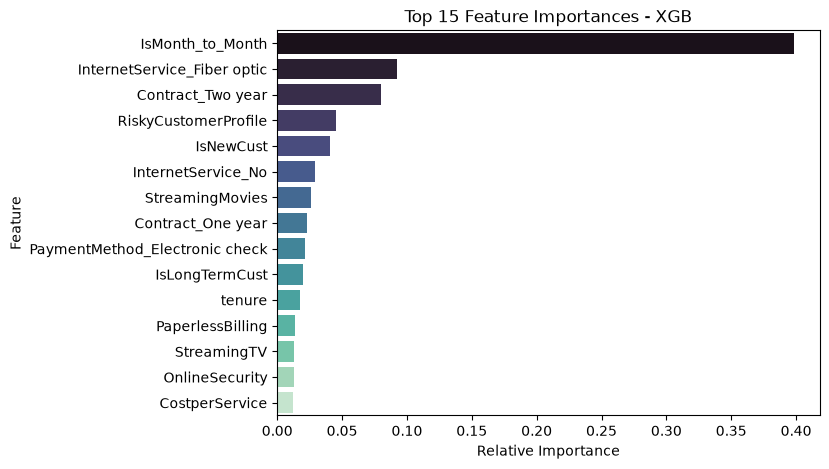

In [6]:
# Feature Importance

feature_imp = pd.DataFrame({
    'Feature' : x_test.columns,
    'Importance' : xgb_model.feature_importances_
}).sort_values(by = 'Importance', ascending = False)

plt.figure(figsize = (7,5))
sns.barplot(data = feature_imp.head(15), x = 'Importance', y = 'Feature', palette = 'mako')

plt.title("Top 15 Feature Importances - XGB")
plt.xlabel("Relative Importance")
plt.ylabel("Feature")
plt.show()